# COE 476 (Neural Networks and Deep Learning) project: one-class anomaly detection on UCF-Crime-DVS
Convolutional autoencoder (CNN-AE) vs spiking autoencoder (SNN-AE), trained on normal event clips only.
A clip is `T` consecutive 533 ms windows. The anomaly score of a window is its reconstruction error.

**Before running:** put `cache.zip` and `work_meta.zip` in a folder called `data` next to this notebook (a GPU makes training much faster).
Run the cells from top to bottom. If a cell fails, stop and send the error.

| Part | Cells |
|---|---|
| 1 Setup | unpack data, settings |
| 2 Look at the data | split, one window, scaling, training clips |
| 3 Models and training | CNN-AE, SNN-AE, training loop |
| 4 Evaluation | frame-level AUROC and AUPRC, event-count and zero-predictor references |
| 5 Experiments | one run first, then all runs, summary, uncertainty over videos |

## 1. Setup

In [3]:
import os, zipfile
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import snntorch as snn
from snntorch import surrogate, utils
from IPython.display import HTML, display

DATA = Path("data")                                     # cache.zip and work_meta.zip live here
WORK = Path(os.environ.get("WORK_DIR", "work"))         # unpacked cache/, labels/, split_manifest.csv; results are written here too
if not (WORK / "cache").exists():                       # unpack once; never wipe work/, it holds results.csv
    WORK.mkdir(exist_ok=True)
    for z in ("cache.zip", "work_meta.zip"):
        zipfile.ZipFile(DATA / z).extractall(WORK)
print(sorted(p.name for p in WORK.iterdir()))           # expect: cache, labels, prep_info.json, split_manifest.csv

['auroc_vs_T.png', 'backup', 'cache', 'labels', 'prep_info.json', 'results.csv', 'scores', 'split_manifest.csv', 'summary.csv']


In [4]:
# Settings (all in one place)
import copy, json, random, shutil, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, average_precision_score

BACKUP = WORK / "backup"                            # results.csv and summary.csv are copied here after every run
BACKUP.mkdir(exist_ok=True)
(WORK / "scores").mkdir(exist_ok=True)              # per-video window scores of every run (used for the confidence intervals)

SIZE = 64                    # each window is a 2 x 64 x 64 image (OFF and ON events)
FRAMES_PER_WINDOW = 16       # one 533 ms window = 16 video frames
CLASSES = sorted(set(pd.read_csv(WORK / "split_manifest.csv")["class"]) - {"Normal"})
print("anomaly classes in manifest:", CLASSES)
SEEDS = [0, 1, 2]
EPOCHS, BATCH, LR, PATIENCE = 30, 64, 1e-3, 3        # early stopping on validation loss, so 30 is only a ceiling
MAX_WINDOWS_PER_VIDEO = 200  # random clips per training video

CODE_VERSION = "v2"          # bump whenever the model or training code changes, so old results are never mixed in
USE_BN = True                # batch norm in BOTH models (a fair comparison needs the same setting)
SNN_LEARN = True             # SNN-AE: learnable beta and threshold
MATCH_LATENT = True         # True: CNN-AE latent = 32*T channels, so both models have the same total latent size (bump CODE_VERSION if you change it)
RUN_ABLATION = True         # True adds the clip-length ablation (T = 2 and 8), about twice as many runs

anomaly classes in manifest: ['Arson', 'Assault', 'Burglary', 'Explosion', 'Fighting']


## 2. Look at the data
`split_manifest.csv` lists every video with its role (train, val, test) and class. The cache holds, for each video, an array of
shape (number of windows, 2, 64, 64) with event **counts**: channel 0 = OFF events (pixel got darker), channel 1 = ON events (got brighter).

In [5]:
manifest = pd.read_csv(WORK / "split_manifest.csv")
print(manifest.groupby(["role", "class"]).size())

def load_counts(video):
    return np.load(WORK / "cache" / f"{video}.npz")["w"]

video = manifest[manifest["class"] == "Explosion"].video.iloc[2]
w = load_counts(video)
print(video, "-> array shape", w.shape, w.dtype, "(windows, polarity, height, width)")

role   class    
test   Arson          9
       Assault        3
       Burglary      13
       Explosion     21
       Fighting       5
       Normal        22
train  Normal       103
val    Normal        22
dtype: int64
Explosion007_x264 -> array shape (1017, 2, 64, 64) uint16 (windows, polarity, height, width)


### Dataset overview: duration and event-count distributions

Duration and event count are calculated per video in the processed cache. One window represents approximately 533 ms.

           videos  mean_duration_s  mean_event_count
class                                               
Arson           9           102.52      3.924203e+07
Assault         3           293.69      1.223689e+08
Burglary       13           195.49      2.901489e+07
Explosion      21           102.68      2.806576e+07
Fighting        5            81.49      3.186232e+07
Normal        147            89.56      2.007995e+07


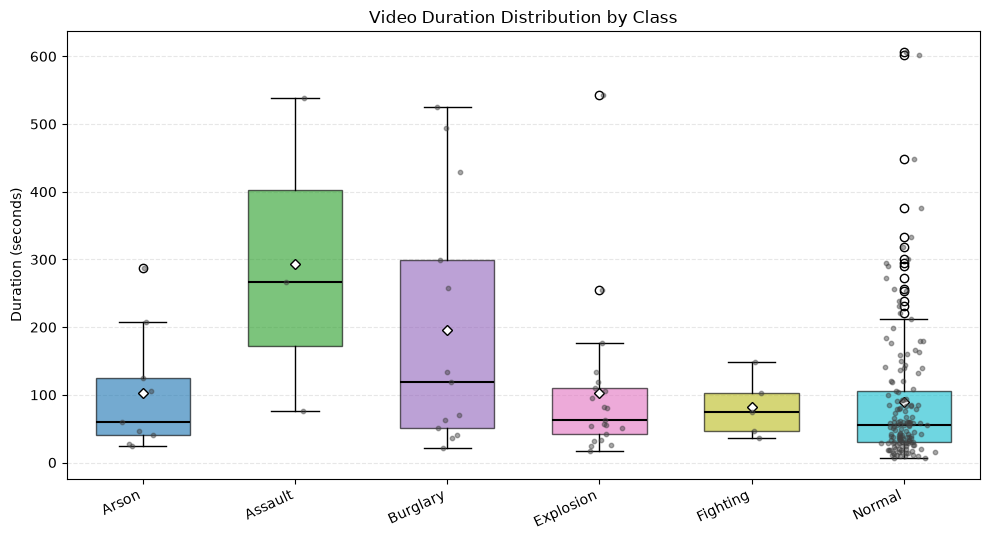

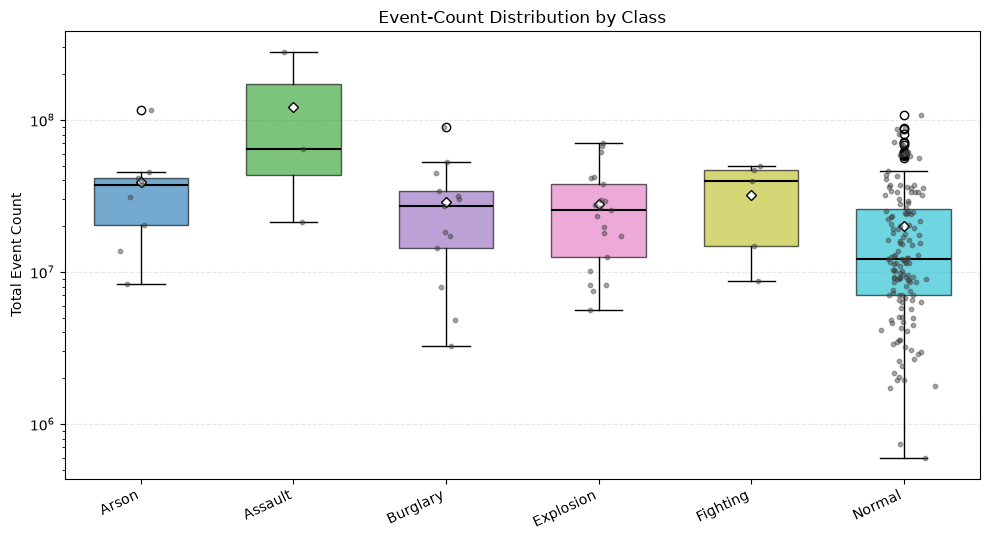

In [8]:
# Build one row per video for duration and event-count visualisation.
WINDOW_US = int(json.loads((WORK / "prep_info.json").read_text())["window_us"])

video_stats = []
for row in manifest.to_dict("records"):
    w = load_counts(row["video"])
    n_windows = w.shape[0]
    video_stats.append({
        "video": row["video"],
        "role": row["role"],
        "class": row["class"],
        "duration_seconds": n_windows * WINDOW_US / 1_000_000,
        "event_count": int(w.sum()),
        "mean_events_per_window": float(w.sum(axis=(1, 2, 3)).mean()),
    })

video_stats = pd.DataFrame(video_stats)
class_order = [c for c in sorted(set(video_stats["class"])) if c != "Normal"] + ["Normal"]
print(video_stats.groupby("class").agg(
    videos=("video", "count"),
    mean_duration_s=("duration_seconds", "mean"),
    mean_event_count=("event_count", "mean"),
).round(2).reindex(class_order))

def boxplot_by_class(column, ylabel, title, filename, log_scale=False):
    fig, ax = plt.subplots(figsize=(10, 5.5))
    data = [video_stats.loc[video_stats["class"] == c, column].to_numpy()
            for c in class_order]
    positions = np.arange(len(class_order))

    bp = ax.boxplot(
        data,
        positions=positions,
        widths=0.62,
        patch_artist=True,
        showmeans=True,
        meanprops={"marker": "D", "markerfacecolor": "white", "markeredgecolor": "black", "markersize": 5},
        medianprops={"color": "black", "linewidth": 1.5},
    )
    colors = plt.cm.tab10(np.linspace(0, 1, len(class_order)))
    for patch, color in zip(bp["boxes"], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.62)

    rng = np.random.default_rng(42)
    for i, values in enumerate(data):
        jitter = rng.normal(0, 0.07, size=len(values))
        ax.scatter(i + jitter, values, s=10, color="0.25", alpha=0.45, zorder=3)

    ax.set_xticks(positions)
    ax.set_xticklabels(class_order, rotation=25, ha="right")
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.3)
    if log_scale:
        ax.set_yscale("log")
    fig.tight_layout()
    fig.savefig(WORK / filename, dpi=300, bbox_inches="tight")
    plt.show()

boxplot_by_class(
    "duration_seconds",
    "Duration (seconds)",
    "Video Duration Distribution by Class",
    "duration_distribution_by_class.png",
)

boxplot_by_class(
    "event_count",
    "Total Event Count",
    "Event-Count Distribution by Class",
    "event_count_distribution_by_class.png",
    log_scale=True,
)


In [8]:
from matplotlib import animation
from IPython.display import HTML

def animate_windows(windows, start=0, stop=None, step=1, interval=100):
    """Animate selected event-count windows for OFF and ON polarities."""
    if stop is None:
        stop = len(windows)

    frame_indices = np.arange(start, stop, step)
    if len(frame_indices) == 0:
        raise ValueError("The selected frame range is empty")

    fig, ax = plt.subplots(1, 2, figsize=(8, 4))
    vmax = max(1, int(windows[frame_indices].max()))
    ims = []
    titles = ["OFF events", "ON events"]

    for c, name in enumerate(titles):
        im = ax[c].imshow(windows[frame_indices[0], c], cmap="gray", vmin=0, vmax=vmax)
        ax[c].set_title(f"{name}, window {frame_indices[0]}")
        ax[c].axis("off")
        ims.append(im)

    fig.suptitle(video)
    fig.tight_layout()

    def update(frame_index):
        for c, im in enumerate(ims):
            im.set_data(windows[frame_index, c])
            ax[c].set_title(f"{titles[c]}, window {frame_index}")
        return ims

    anim = animation.FuncAnimation(
        fig,
        update,
        frames=frame_indices,
        interval=interval,
        blit=False
    )
    plt.close(fig)
    return anim

# Animate windows 0-49 at 10 frames per second.
anim = animate_windows(w, start=0, stop=50, step=1, interval=100)
HTML(anim.to_jshtml())

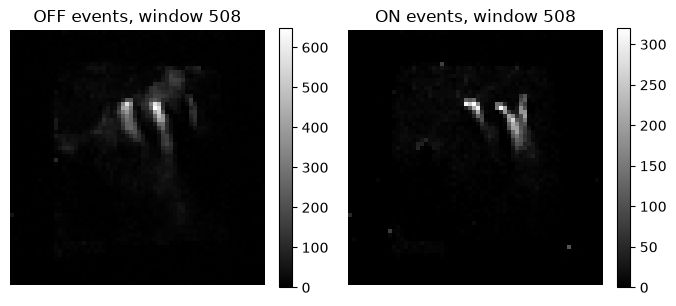

In [9]:
# One window as an image: how many events happened at each of the 64 x 64 cells
k = len(w) // 2
fig, ax = plt.subplots(1, 2, figsize=(8, 4))
for c, name in enumerate(["OFF events", "ON events"]):
    im = ax[c].imshow(w[k, c], cmap="gray"); ax[c].set_title(f"{name}, window {k}"); ax[c].axis("off")
    plt.colorbar(im, ax=ax[c], fraction=0.046)
plt.show()

### Scaling the counts
Counts range from 0 to thousands, so we squash them: **log1p**, then divide by **one fixed constant** (log1p of the 99.9th percentile of
non-zero *training* counts), then clip to [0, 1]. `normalize=True` is the proposed advancement: first divide each window by its own mean
count (per-window event-rate normalization). The normalization formula is a placeholder until it is agreed with the teammate.

In [10]:
def maybe_normalize(counts, normalize):
    x = counts.astype(np.float32)
    if normalize:                                             # per window; works for (n, 2, H, W) and (n, T, 2, H, W)
        x = x / np.maximum(x.mean(axis=(-3, -2, -1), keepdims=True), 1e-6)
    return x

def fit_const(counts, normalize):
    x = maybe_normalize(counts, normalize)
    return float(np.log1p(np.percentile(x[x > 0], 99.9)))    # call on TRAINING windows only

def prepare(counts, normalize, const):
    x = maybe_normalize(counts, normalize)
    return np.clip(np.log1p(x) / const, 0, 1).astype(np.float32)

# demo on the window above
const = fit_const(w, False)
x = prepare(w[k:k + 1], False, const)
print("constant:", round(const, 2), "| raw max count:", w[k].max(), "| scaled range:", x.min(), "to", x.max())
print("raw counts   of a few non-zero cells:", w[k][w[k] > 0][:6])
print("scaled values of the same cells     :", x[0][w[k] > 0][:6].round(3))

constant: 6.14 | raw max count: 648 | scaled range: 0.0 to 1.0
raw counts   of a few non-zero cells: [1 1 1 2 2 3]
scaled values of the same cells     : [0.113 0.113 0.113 0.179 0.179 0.226]


### Training and validation clips
The models only ever see **normal** clips. A clip is `T` consecutive windows. We take up to `MAX_WINDOWS_PER_VIDEO` random clips per training video
to keep memory small. The partial last window of every video is dropped (in training and in testing).

In [11]:
def sample_clips(videos, k, T, seed):
    rng = np.random.RandomState(seed)
    out = []
    for v in videos:
        c = load_counts(v)[:-1]                              # drop the partial last window
        n_starts = max(len(c) - T + 1, 0)
        starts = np.sort(rng.permutation(n_starts)[:k])
        if len(starts):                                      # videos shorter than T windows give no clip
            out.append(np.stack([c[s:s + T] for s in starts]))   # (<=k, T, 2, 64, 64)
    return np.concatenate(out)                               # (N, T, 2, 64, 64), uint16

train_videos = manifest[manifest.role == "train"].video
val_videos = manifest[manifest.role == "val"].video

_clips = {}
def get_clips(T):
    """Train and validation clips for clip length T (only one T is kept in memory at a time)."""
    if T not in _clips:
        _clips.clear()
        _clips[T] = (sample_clips(train_videos, MAX_WINDOWS_PER_VIDEO, T, 0),
                     sample_clips(val_videos, MAX_WINDOWS_PER_VIDEO, T, 0))
    return _clips[T]

tr_counts, va_counts = get_clips(4)
print("train clips:", tr_counts.shape, "| val clips:", va_counts.shape)

train clips: (11090, 4, 2, 64, 64) | val clips: (2035, 4, 2, 64, 64)


## 3. Models and training
Both models use the **same layers and the same batch-norm setting** (`USE_BN`). They differ in the neuron and in how time is handled:
- **CNN-AE** (ReLU): the `T` windows of a clip are stacked as `2T` channels and the whole clip is rebuilt at once.
- **SNN-AE** (spiking leaky integrate-and-fire): one window per timestep; the membrane potential carries information from one window to the next,
  and the `T` rebuilt windows are stacked. Surrogate gradients let it train with backprop. Beta and the threshold are learnable (`SNN_LEARN`).

Each window is shrunk 64 -> 32 -> 16 -> 8 to a 32 x 8 x 8 latent, then rebuilt. **Caveat:** the SNN-AE has one such latent per window
(T times more numbers in total) while the CNN-AE has one per clip, unless `MATCH_LATENT = True`. The CNN-AE's first and last layers also grow with T,
so parameter counts differ a little (printed below).

In [12]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

def layers(act, c_in, c_out, latent=32, bn=False):
    mods = []
    def add(layer, ch, act_on=True):
        mods.append(layer)
        if act_on:
            if bn: mods.append(nn.BatchNorm2d(ch))
            mods.append(act())
    add(nn.Conv2d(c_in, 16, 3, 2, 1), 16)                    # encoder: 64 -> 32
    add(nn.Conv2d(16, 32, 3, 2, 1), 32)                      #          32 -> 16
    add(nn.Conv2d(32, 64, 3, 2, 1), 64)                      #          16 -> 8
    add(nn.Conv2d(64, latent, 3, 1, 1), latent, act_on=False)    # latent, no activation
    add(nn.ConvTranspose2d(latent, 64, 3, 1, 1), 64)         # decoder:  8 -> 8
    add(nn.ConvTranspose2d(64, 32, 4, 2, 1), 32)             #           8 -> 16
    add(nn.ConvTranspose2d(32, 16, 4, 2, 1), 16)             #          16 -> 32
    add(nn.ConvTranspose2d(16, c_out, 4, 2, 1), c_out, act_on=False)   # 32 -> 64, linear output
    return nn.Sequential(*mods)

class SNNAE(nn.Module):
    """One window per timestep; membrane potentials carry information across the windows of a clip."""
    def __init__(self, T, bn=False, learn=False):
        super().__init__()
        kw = dict(beta=0.9, spike_grad=surrogate.fast_sigmoid(), init_hidden=True)
        if learn: kw.update(learn_beta=True, learn_threshold=True)
        self.net = layers(lambda: snn.Leaky(**kw), 2, 2, bn=bn)
    def forward(self, x):                                    # x: (B, T, 2, 64, 64)
        utils.reset(self.net)                                # clear membrane potentials
        return torch.stack([self.net(x[:, t]) for t in range(x.shape[1])], dim=1)

class ConvAE(nn.Module):
    """The T windows of a clip are stacked as 2T channels."""
    def __init__(self, T, bn=False):
        super().__init__()
        self.net = layers(nn.ReLU, 2 * T, 2 * T, latent=32 * T if MATCH_LATENT else 32, bn=bn)
    def forward(self, x):
        return self.net(x.flatten(1, 2)).view(x.shape)

def build(name, T):
    if name == "cnn": return ConvAE(T, bn=USE_BN)
    if name == "snn": return SNNAE(T, bn=USE_BN, learn=SNN_LEARN)
    raise ValueError(f"unknown model {name!r}")

def run_name(model, normalize, T, seed):
    return f"{CODE_VERSION}_{model}_norm{int(normalize)}_T{T}_s{seed}"

# self-test: both models must keep the input shape; the printed names show that the CNN-AE really is a ConvAE
for T_ in (2, 4, 8):
    xx = torch.rand(2, T_, 2, 64, 64)
    for name in ("cnn", "snn"):
        m = build(name, T_)
        print(f"T={T_} {name}: {type(m).__name__:7s} {sum(p.numel() for p in m.parameters()):>8,} parameters | output shape {tuple(m(xx).shape)}")

device: cuda
T=2 cnn: ConvAE   140,068 parameters | output shape (2, 2, 2, 64, 64)
T=2 snn: SNNAE    102,382 parameters | output shape (2, 2, 2, 64, 64)
T=4 cnn: ConvAE   215,464 parameters | output shape (2, 4, 2, 64, 64)
T=4 snn: SNNAE    102,382 parameters | output shape (2, 4, 2, 64, 64)
T=8 cnn: ConvAE   366,256 parameters | output shape (2, 8, 2, 64, 64)
T=8 snn: SNNAE    102,382 parameters | output shape (2, 8, 2, 64, 64)


In [13]:
class ClipTensor(torch.utils.data.Dataset):
    def __init__(self, counts, normalize, const):
        self.counts, self.normalize, self.const = counts, normalize, const
    def __len__(self): return len(self.counts)
    def __getitem__(self, i):
        return torch.from_numpy(prepare(self.counts[i], self.normalize, self.const))   # (T, 2, 64, 64) float32

In [14]:
def train_model(model_name, normalize, T, seed, epochs=EPOCHS):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    tr_counts, va_counts = get_clips(T)
    const = fit_const(tr_counts[:, 0], normalize)
    Xva = torch.tensor(prepare(va_counts, normalize, const)).to(device)      # small enough to keep
    print(f"  zero-predictor val MSE (reference): {(Xva ** 2).mean().item():.5f}")
    net = build(model_name, T).to(device)
    opt = torch.optim.Adam(net.parameters(), lr=LR)
    loss_fn = nn.MSELoss()
    loader = DataLoader(ClipTensor(tr_counts, normalize, const), batch_size=BATCH, shuffle=True)

    best, bad, best_state, history = 1e9, 0, None, []
    for epoch in range(epochs):
        net.train(); total = 0
        for xb in loader:                                   # a batch tensor, not a 1-tuple
            xb = xb.to(device)
            loss = loss_fn(net(xb), xb)
            opt.zero_grad(); loss.backward(); opt.step()
            total += loss.item() * len(xb)
        net.eval()
        with torch.no_grad():
            val = sum(loss_fn(net(Xva[i:i + 256]), Xva[i:i + 256]).item() * len(Xva[i:i + 256])
                      for i in range(0, len(Xva), 256)) / len(Xva)
        history.append((total / len(tr_counts), val))
        print(f"  epoch {epoch + 1}: train {history[-1][0]:.5f}  val {val:.5f}")
        if val < best:
            best, bad, best_state = val, 0, copy.deepcopy(net.state_dict())
        else:
            bad += 1
            if bad >= PATIENCE:
                break
    net.load_state_dict(best_state)
    net.eval()
    return net, const, history

## 4. Evaluation
Every test video is cut into windows, each window gets a score (reconstruction error), and the score is given to the 16 video frames the window covers.
We then compare with the official 0/1 frame labels. The event stream ends 0.7 to 3 seconds before the video does, so the last few labelled frames
(no event data) are dropped.

Metrics (anomalous frame = positive): **AUROC** and **AUPRC** pooled over all test frames; `chance` is the AUPRC of a random scorer (= share of anomalous frames).
`video_auroc` is the AUROC computed inside each anomalous video and then averaged. It matters because the pooled number is dominated by
a few busy or long videos, and it is the number that is not helped by "busy video vs quiet video" differences.
Classes with only a few test videos (see the table in section 2) cannot support claims on their own.

In [15]:
test_data = []
for _, r in manifest[manifest.role == "test"].iterrows():
    counts = load_counts(r.video)[:-1]                        # drop the partial last window, as in training
    label_file = WORK / "labels" / f"{r.video}.npy"
    y = np.load(label_file) if label_file.exists() else np.zeros(len(counts) * FRAMES_PER_WINDOW, dtype=np.uint8)  # normals from the official train list: all normal
    n = min(len(y), len(counts) * FRAMES_PER_WINDOW)          # frames that have event data
    test_data.append(dict(video=r.video, cls=r["class"], counts=counts, y=y[:n]))
print(len(test_data), "test videos,", sum(len(d["y"]) for d in test_data), "frames,",
      f"{np.concatenate([d['y'] for d in test_data]).mean():.3f} of them anomalous")

def metrics(y, s):
    if y.min() == y.max():
        return np.nan, np.nan, float(y.mean())
    return roc_auc_score(y, s), average_precision_score(y, s), float(y.mean())

def evaluate_scores(score_fn):
    """score_fn(counts) -> one score per window. Returns metric rows and per-video items."""
    items = []
    for d in test_data:
        n = len(d["y"])
        items.append(dict(video=d["video"], cls=d["cls"], y=d["y"],
                          score=np.repeat(score_fn(d["counts"]), FRAMES_PER_WINDOW)[:n],
                          count=np.repeat(d["counts"].sum(axis=(1, 2, 3)).astype(float), FRAMES_PER_WINDOW)[:n]))
    scopes = {"pooled": items}
    for c in CLASSES:                                         # a class = its anomalous videos + all normal test videos
        scopes[c] = [i for i in items if i["cls"] in (c, "Normal")]
    rows = []
    for scope, its in scopes.items():
        y = np.concatenate([i["y"] for i in its]); s = np.concatenate([i["score"] for i in its])
        cnt = np.concatenate([i["count"] for i in its])
        auroc, auprc, chance = metrics(y, s)
        per_video = [metrics(i["y"], i["score"])[0] for i in its if i["y"].max() > 0 and i["y"].min() == 0]
        rows.append(dict(scope=scope, auroc=auroc, auprc=auprc, chance=chance,
                         video_auroc=float(np.mean(per_video)) if per_video else np.nan,
                         corr_with_count=float(np.corrcoef(s, cnt)[0, 1]) if s.std() > 0 and cnt.std() > 0 else np.nan))
    return rows, items

def window_scores(net, counts, normalize, const, T):
    """Reconstruction error per window: every window is scored by all clips that contain it, then averaged."""
    x = torch.tensor(prepare(counts, normalize, const))        # (n, 2, 64, 64)
    n = len(x)
    if n < T:                                                  # very short video: repeat the last window
        x = torch.cat([x, x[-1:].repeat(T - n, 1, 1, 1)])
    m = len(x); err = np.zeros(m); cover = np.zeros(m)
    starts = np.arange(m - T + 1)
    net.eval()
    with torch.no_grad():
        for i in range(0, len(starts), 128):
            ss = starts[i:i + 128]
            b = torch.stack([x[s:s + T] for s in ss]).to(device)              # (B, T, 2, 64, 64)
            e = ((net(b) - b) ** 2).mean(dim=(2, 3, 4)).cpu().numpy()         # error per window in the clip
            for s, row in zip(ss, e):
                err[s:s + T] += row; cover[s:s + T] += 1
    return (err / np.maximum(cover, 1))[:n]

73 test videos, 271744 frames, 0.164 of them anomalous


### Reference with no learning: event count
Score of a window = its total number of events. A neural network is only worth something if it beats this.

In [16]:
ref_rows, _ = evaluate_scores(lambda counts: counts.sum(axis=(1, 2, 3)).astype(float))
for r in ref_rows:
    r.update(run="event_count", model="event_count", normalize=0, T=0, seed=-1)

# zero predictor: score = energy of the scaled window (what a network that outputs all zeros would give)
tr_ref, _ = get_clips(4)
zero_rows = []
for normalize in (False, True):
    c = fit_const(tr_ref[:, 0], normalize)
    zr, _ = evaluate_scores(lambda counts: (prepare(counts, normalize, c) ** 2).mean(axis=(1, 2, 3)))
    for r in zr:
        r.update(run=f"zero_norm{int(normalize)}", model="zero", normalize=int(normalize), T=0, seed=-1)
    zero_rows += zr

display(pd.DataFrame(ref_rows + zero_rows)[["run", "scope", "auroc", "auprc", "chance", "video_auroc"]].round(3))

,run,scope,auroc,auprc,chance,video_auroc
0,event_count,pooled,0.667,0.338,0.164,0.712
1,event_count,Arson,0.486,0.142,0.087,0.687
2,event_count,Assault,0.922,0.548,0.092,0.710
3,event_count,Burglary,0.545,0.146,0.114,0.709
4,event_count,Explosion,0.667,0.111,0.059,0.746
5,event_count,Fighting,0.780,0.143,0.057,0.626
6,zero_norm0,pooled,0.651,0.350,0.164,0.716
7,zero_norm0,Arson,0.484,0.153,0.087,0.687
8,zero_norm0,Assault,0.931,0.615,0.092,0.715
9,zero_norm0,Burglary,0.496,0.144,0.114,0.670


## 5. Experiments
First **one** run, so you can see every step (CNN-AE, no normalization, T=4, seed 0).

In [17]:
_tmpl = {}
def template_mse(T, normalize):
    """Validation MSE of one constant clip (the training mean) = the collapsed-network reference."""
    if (T, normalize) not in _tmpl:
        tr, va = get_clips(T)
        c = fit_const(tr[:, 0], normalize)
        m = prepare(tr[::10], normalize, c).mean(0)
        _tmpl[(T, normalize)] = float(((prepare(va, normalize, c) - m) ** 2).mean())
    return _tmpl[(T, normalize)]

def run(model_name, normalize, T, seed):
    name = run_name(model_name, normalize, T, seed)
    print("training", name)
    net, const, history = train_model(model_name, normalize, T, seed)
    rows, items = evaluate_scores(lambda counts: window_scores(net, counts, normalize, const, T))
    val_mse, tmpl = min(h[1] for h in history), template_mse(T, normalize)
    print(f"  best val MSE {val_mse:.5f} | template {tmpl:.5f} | collapsed: {val_mse > 0.95 * tmpl}")
    # keep every window score so confidence intervals can be computed later (a frame score is its window's score repeated)
    np.savez_compressed(WORK / "scores" / f"{name}.npz",
                        **{i["video"]: i["score"][::FRAMES_PER_WINDOW].astype(np.float32) for i in items})
    for r in rows:
        r.update(run=name, model=model_name, normalize=int(normalize), T=T, seed=seed,
                 val_mse=val_mse, template_mse=tmpl, collapsed=bool(val_mse > 0.95 * tmpl))
    del net
    if device == "cuda":
        torch.cuda.empty_cache()
    return rows, history, items

training v2_cnn_norm0_T4_s0
  zero-predictor val MSE (reference): 0.07399
  epoch 1: train 0.01878  val 0.01181
  epoch 2: train 0.01140  val 0.01050
  epoch 3: train 0.01026  val 0.01004
  epoch 4: train 0.00952  val 0.00922
  epoch 5: train 0.00912  val 0.00935
  epoch 6: train 0.00852  val 0.00846
  epoch 7: train 0.00820  val 0.00793
  epoch 8: train 0.00788  val 0.00774
  epoch 9: train 0.00782  val 0.00773
  epoch 10: train 0.00755  val 0.00738
  epoch 11: train 0.00744  val 0.00742
  epoch 12: train 0.00721  val 0.00700
  epoch 13: train 0.00705  val 0.00684
  epoch 14: train 0.00694  val 0.00712
  epoch 15: train 0.00682  val 0.00676
  epoch 16: train 0.00669  val 0.00693
  epoch 17: train 0.00661  val 0.00661
  epoch 18: train 0.00656  val 0.00654
  epoch 19: train 0.00649  val 0.00681
  epoch 20: train 0.00651  val 0.00682
  epoch 21: train 0.00639  val 0.00638
  epoch 22: train 0.00631  val 0.00621
  epoch 23: train 0.00626  val 0.00619
  epoch 24: train 0.00616  val 0.00637

,scope,auroc,auprc,chance,video_auroc,corr_with_count
0,pooled,0.685,0.381,0.164,0.701,0.709
1,Arson,0.549,0.168,0.087,0.663,0.731
2,Assault,0.951,0.765,0.092,0.743,0.818
3,Burglary,0.633,0.172,0.114,0.749,0.755
4,Explosion,0.553,0.107,0.059,0.701,0.674
5,Fighting,0.771,0.122,0.057,0.619,0.748


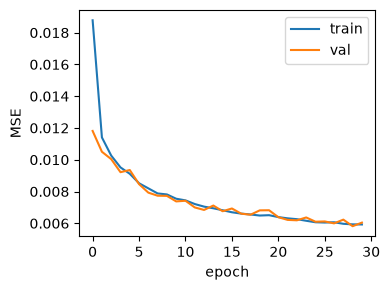

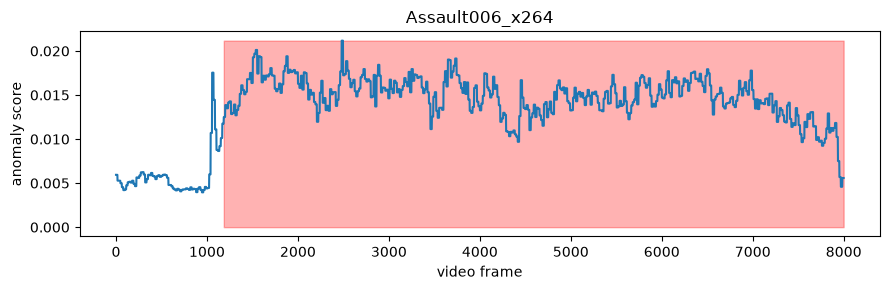

In [18]:
rows, history, items = run("cnn", False, 4, 0)
display(pd.DataFrame(rows)[["scope", "auroc", "auprc", "chance", "video_auroc", "corr_with_count"]].round(3))

# Loss curves, and the anomaly score over time of one anomalous test video (red = labelled anomalous frames)
plt.figure(figsize=(4, 3)); plt.plot([h[0] for h in history], label="train"); plt.plot([h[1] for h in history], label="val")
plt.xlabel("epoch"); plt.ylabel("MSE"); plt.legend(); plt.tight_layout(); plt.show()

def plot_timeline(items, name=None):
    cand = [i for i in items if (i["video"].startswith(name) if name else i["y"].max() > 0)]
    i = max(cand, key=lambda i: i["y"].sum())                 # the video with the most anomalous frames
    plt.figure(figsize=(9, 3)); plt.plot(i["score"])
    plt.fill_between(range(len(i["y"])), 0, i["score"].max(), where=i["y"] > 0, alpha=0.3, color="red")
    plt.xlabel("video frame"); plt.ylabel("anomaly score"); plt.title(i["video"]); plt.tight_layout(); plt.show()

plot_timeline(items)

### All experiments
Main comparison at clip length T=4: CNN-AE and SNN-AE, each with normalization off and on, 3 seeds each (12 runs).
With `RUN_ABLATION = True` the clip-length ablation (T = 2 and 8, normalization off) is added.
Results are saved after every run. If the notebook stops, run the setup cells again, then this cell: finished runs are skipped.
Results of older code versions are moved to a separate file, so they never mix with these runs.

In [19]:
configs = [("cnn", False, 4), ("cnn", True, 4), ("snn", False, 4), ("snn", True, 4)]
if RUN_ABLATION:
    configs += [(m, False, t) for t in (2, 8) for m in ("cnn", "snn")]

results_file = WORK / "results.csv"

# set aside results of an older code version, once, so they never mix with the new runs
if results_file.exists():
    old = pd.read_csv(results_file)
    learned = old[~old.model.isin(["event_count", "zero"])]
    if len(learned) and not learned.run.astype(str).str.startswith(CODE_VERSION + "_").all():
        stamp = time.strftime("%Y%m%d_%H%M%S")
        shutil.move(results_file, WORK / f"results_older_{stamp}.csv")
        if (WORK / "summary.csv").exists():
            shutil.move(WORK / "summary.csv", WORK / f"summary_older_{stamp}.csv")
        print("older results moved aside:", f"results_older_{stamp}.csv")

results = pd.read_csv(results_file) if results_file.exists() else pd.DataFrame()
if len(results):
    results = results[~results.model.isin(["event_count", "zero"])]
results = pd.concat([results, pd.DataFrame(ref_rows), pd.DataFrame(zero_rows)])

for model_name, normalize, T in configs:
    for seed in SEEDS:
        name = run_name(model_name, normalize, T, seed)
        if name in set(results.run):
            print("skip", name); continue
        rows, _, _ = run(model_name, normalize, T, seed)
        results = pd.concat([results, pd.DataFrame(rows)])
        results.to_csv(results_file, index=False)
        shutil.copy(results_file, BACKUP / "results.csv")
print("done:", results.run.nunique(), "runs in results.csv")

training v2_cnn_norm0_T4_s0
  zero-predictor val MSE (reference): 0.07399
  epoch 1: train 0.01878  val 0.01181
  epoch 2: train 0.01140  val 0.01050
  epoch 3: train 0.01025  val 0.01011
  epoch 4: train 0.00951  val 0.00919
  epoch 5: train 0.00911  val 0.00930
  epoch 6: train 0.00851  val 0.00848
  epoch 7: train 0.00819  val 0.00791
  epoch 8: train 0.00787  val 0.00773
  epoch 9: train 0.00781  val 0.00769
  epoch 10: train 0.00754  val 0.00739
  epoch 11: train 0.00743  val 0.00741
  epoch 12: train 0.00720  val 0.00698
  epoch 13: train 0.00704  val 0.00684
  epoch 14: train 0.00694  val 0.00710
  epoch 15: train 0.00682  val 0.00677
  epoch 16: train 0.00669  val 0.00697
  epoch 17: train 0.00660  val 0.00661
  epoch 18: train 0.00654  val 0.00656
  epoch 19: train 0.00648  val 0.00679
  epoch 20: train 0.00650  val 0.00679
  epoch 21: train 0.00639  val 0.00639
  epoch 22: train 0.00634  val 0.00628
  epoch 23: train 0.00633  val 0.00616
  epoch 24: train 0.00620  val 0.00634

In [20]:
# Main results table: mean and std over the 3 seeds
r = results.copy()
summary = r.groupby(["model", "normalize", "T", "scope"]).agg(
    auroc=("auroc", "mean"), auroc_std=("auroc", "std"),
    auprc=("auprc", "mean"), auprc_std=("auprc", "std"),
    chance=("chance", "mean"),
    video_auroc=("video_auroc", "mean"), video_auroc_std=("video_auroc", "std"),
    corr_with_count=("corr_with_count", "mean"),
    n_seeds=("seed", "count")).reset_index()
summary.to_csv(WORK / "summary.csv", index=False)
shutil.copy(WORK / "summary.csv", BACKUP / "summary.csv")
cols = ["model", "normalize", "T", "auroc", "auroc_std", "video_auroc", "video_auroc_std", "auprc", "chance", "corr_with_count", "n_seeds"]
summary[summary.scope == "pooled"][cols].sort_values(["model", "normalize", "T"]).round(3)

,model,normalize,T,auroc,auroc_std,video_auroc,video_auroc_std,auprc,chance,corr_with_count,n_seeds
5,cnn,0,2,0.675,0.001,0.655,0.008,0.387,0.164,0.494,3
11,cnn,0,4,0.687,0.002,0.706,0.006,0.381,0.164,0.712,3
17,cnn,0,8,0.689,0.001,0.707,0.001,0.360,0.164,0.787,3
23,cnn,1,4,0.629,0.022,0.543,0.037,0.288,0.164,0.087,3
29,event_count,0,0,0.667,NaN,0.712,NaN,0.338,0.164,1.000,1
35,snn,0,2,0.696,0.001,0.710,0.003,0.361,0.164,0.841,3
41,snn,0,4,0.694,0.000,0.707,0.002,0.368,0.164,0.798,3
47,snn,0,8,0.695,0.000,0.709,0.001,0.358,0.164,0.822,3
53,snn,1,4,0.671,0.001,0.610,0.006,0.329,0.164,0.296,3
59,zero,0,0,0.651,NaN,0.716,NaN,0.350,0.164,0.900,1


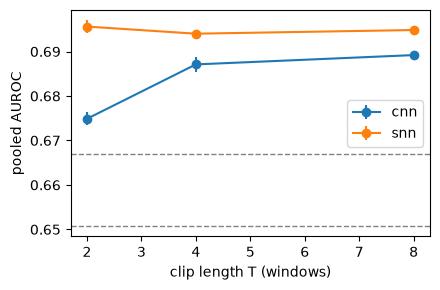

In [21]:
# Clip-length ablation: pooled AUROC against T (normalization off), with the activity-only references as dashed lines
s = summary[(summary.scope == "pooled") & (summary.normalize == 0) & summary.model.isin(["cnn", "snn"])]
if s["T"].nunique() > 1:
    plt.figure(figsize=(4.5, 3))
    for m, g in s.groupby("model"):
        g = g.sort_values("T"); plt.errorbar(g["T"], g.auroc, yerr=g.auroc_std.fillna(0), marker="o", label=m)
    for m in ("event_count", "zero"):
        ref = summary[(summary.model == m) & (summary.scope == "pooled") & (summary.normalize == 0)]
        if len(ref): plt.axhline(ref.auroc.iloc[0], ls="--", color="gray", lw=1)
    plt.xlabel("clip length T (windows)"); plt.ylabel("pooled AUROC"); plt.legend(); plt.tight_layout()
    plt.savefig(WORK / "auroc_vs_T.png", dpi=150); plt.show()
else:
    print("Only T = 4 has been run. Set RUN_ABLATION = True in the settings cell and rerun the experiments cell for the clip-length ablation.")

### Uncertainty over test videos
The std over seeds only measures training randomness. The test set has few videos (a few per class), so the real uncertainty is much larger.
Here the **videos** are resampled (frames of one video are not independent). Window scores are averaged over the 3 seeds first,
so these AUROCs can differ slightly from the mean over seeds in the table above.

In [23]:
def load_items(run_names):
    """Average the saved window scores over runs (seeds) and rebuild per-video frame items."""
    zs = [np.load(WORK / "scores" / f"{n}.npz") for n in run_names]
    return [dict(video=d["video"], cls=d["cls"], y=d["y"],
                 score=np.repeat(np.mean([z[d["video"]] for z in zs], axis=0), FRAMES_PER_WINDOW)[:len(d["y"])])
            for d in test_data]

def event_count_items():
    return [dict(video=d["video"], cls=d["cls"], y=d["y"],
                 score=np.repeat(d["counts"].sum(axis=(1, 2, 3)).astype(float), FRAMES_PER_WINDOW)[:len(d["y"])])
            for d in test_data]

def bootstrap_auc(a, b=None, n=300, step=4, seed=0):
    """95% interval of the pooled AUROC of `a` (and of AUROC(a) - AUROC(b)), resampling whole videos.
    Frames are subsampled by `step` to keep it fast."""
    rng = np.random.default_rng(seed)
    ys = [i["y"][::step] for i in a]
    sa = [i["score"][::step] for i in a]
    sb = [i["score"][::step] for i in b] if b is not None else None
    out_a, out_d = [], []
    for _ in range(n):
        idx = rng.integers(0, len(a), len(a))
        y = np.concatenate([ys[j] for j in idx])
        if y.min() == y.max():
            continue
        ra = roc_auc_score(y, np.concatenate([sa[j] for j in idx])); out_a.append(ra)
        if sb is not None:
            out_d.append(ra - roc_auc_score(y, np.concatenate([sb[j] for j in idx])))
    ci = lambda v: tuple(float(x) for x in np.percentile(v, [2.5, 97.5]).round(3))
    return ci(out_a), (ci(out_d) if sb is not None else None)

ec_items = event_count_items()
rows_ci = []
for model in ("cnn", "snn"):
    names = [run_name(model, False, 4, s) for s in SEEDS]
    if not all((WORK / "scores" / f"{n}.npz").exists() for n in names):
        print(model, ": run the experiments cell first"); continue
    items_m = load_items(names)
    for scope in ["pooled"] + CLASSES:
        sel = (lambda its: its) if scope == "pooled" else (lambda its, c=scope: [i for i in its if i["cls"] in (c, "Normal")])
        ci_m, ci_d = bootstrap_auc(sel(items_m), sel(ec_items))
        rows_ci.append(dict(model=model, scope=scope, auroc_ci_low=ci_m[0], auroc_ci_high=ci_m[1],
                            minus_event_count_low=ci_d[0], minus_event_count_high=ci_d[1]))
display(pd.DataFrame(rows_ci))
print("If the interval of 'minus_event_count' contains 0, the model is not shown to beat plain event count.")

,model,scope,auroc_ci_low,auroc_ci_high,minus_event_count_low,minus_event_count_high
0,cnn,pooled,0.563,0.796,-0.018,0.059
1,cnn,Arson,0.431,0.834,0.006,0.111
2,cnn,Assault,0.713,0.991,0.009,0.116
3,cnn,Burglary,0.453,0.804,0.043,0.155
4,cnn,Explosion,0.461,0.717,-0.199,-0.020
5,cnn,Fighting,0.567,0.890,-0.071,0.050
6,snn,pooled,0.576,0.798,-0.011,0.070
7,snn,Arson,0.481,0.854,0.028,0.160
8,snn,Assault,0.705,0.992,0.010,0.099
9,snn,Burglary,0.447,0.800,0.041,0.148


If the interval of 'minus_event_count' contains 0, the model is not shown to beat plain event count.
